# Interview Candidate Selection Predictor

**Aim:** Predict Selected or Not Selected using candidate details and software interview scores.

We compare Logistic Regression, Decision Tree and Random Forest. The dataset is synthetic, so this is a classification demonstration rather than a validated hiring tool.

Run the cells from top to bottom. Sections 1-3 cover preparation, 4-5 cover training and testing, 6-9 cover predictions and model verification, and Section 10 presents the visual comparisons.

## 1. Read the dataset
Import the basic libraries and load the raw CSV.

In [1]:
import pandas as pd
import numpy as np
from software_schema import DATA, FEATURES

raw = pd.read_csv(DATA / "raw_entry_exercise.csv")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (9200, 14)


,candidate_id,cgpa,internships,projects,coding_correctness,dsa,debugging,oop,dbms,os_networks,project_review,problem_solving,communication,selection_status
0,SYN-04847,7.23,1.0,5.0,NaN,70.0,77.0,NaN,82.0,64.0,78.0,78.0,53.0,Selected
1,SYN-02353,7.27,1.0,1.0,27.0,49.0,50.0,66.0,43.0,66.0,50.0,46.0,31.0,Not Selected
2,SYN-00888,7.54,0.0,8.0,66.0,64.0,53.0,80.0,51.0,64.0,76.0,50.0,57.0,Selected
3,SYN-07858,8.10,0.0,2.0,73.0,81.0,47.0,92.0,100.0,78.0,89.0,63.0,57.0,Selected
4,SYN-05018,7.46,0.0,2.0,53.0,72.0,47.0,66.0,77.0,68.0,49.0,56.0,35.0,Not Selected


## 2. Clean the data
Do the cleaning directly with Pandas so each change is visible. Keep the raw data unchanged.

In [2]:
raw.isna().sum()

candidate_id            0
cgpa                  202
internships           206
projects              207
coding_correctness    209
dsa                   204
debugging             204
oop                   203
dbms                  200
os_networks           203
project_review        209
problem_solving       206
communication         202
selection_status        0
dtype: int64

**Standardize text:** remove extra spaces and make the selection labels consistent.

In [3]:
data = raw.copy()
data["candidate_id"] = data["candidate_id"].astype(str).str.strip()
data["selection_status"] = (
    data["selection_status"].astype(str).str.strip().str.lower()
    .map({"selected": "Selected", "not selected": "Not Selected"})
)
data["selection_status"].value_counts(dropna=False)

selection_status
Not Selected    5183
Selected        4017
Name: count, dtype: int64

**Check numeric inputs:** convert invalid text to missing values. Check the allowed ranges; internship and project counts must also be whole numbers. Invalid values become missing rather than being guessed.

In [4]:
from software_schema import RANGES

for column in FEATURES:
    data[column] = pd.to_numeric(data[column], errors="coerce")
    minimum, maximum = RANGES[column]
    outside_range = ~data[column].between(minimum, maximum)
    data.loc[outside_range, column] = np.nan

for column in ["internships", "projects"]:
    fractional_count = data[column].notna() & (data[column] % 1 != 0)
    data.loc[fractional_count, column] = np.nan

data[FEATURES].isna().sum()

cgpa                  202
internships           255
projects              207
coding_correctness    209
dsa                   297
debugging             204
oop                   203
dbms                  200
os_networks           203
project_review        209
problem_solving       206
communication         202
dtype: int64

**Remove exact duplicate copies:** use the ID, inputs and label together. Equal scores alone do not establish that two candidates are duplicates.

In [5]:
before = len(data)
data = data.drop_duplicates(
    subset=["candidate_id"] + FEATURES + ["selection_status"]
)
print("Duplicate copies removed:", before - len(data))

Duplicate copies removed: 200


**Separate records that need review:** keep conflicting IDs, unknown labels, invalid IDs and rows with more than 40% missing inputs out of the modelling set. The 40% cutoff is our stated cleaning rule.

In [6]:
repeated_id = data["candidate_id"].duplicated(keep=False)
unknown_label = data["selection_status"].isna()
invalid_id = ~data["candidate_id"].str.fullmatch(r"SYN-\d{5}")
too_many_missing = data[FEATURES].isna().mean(axis=1) > 0.40
needs_review = repeated_id | unknown_label | invalid_id | too_many_missing

review = data.loc[needs_review].copy()
cleaned = data.loc[~needs_review,
    ["candidate_id"] + FEATURES + ["selection_status"]].copy()
print("Rows kept for review:", len(review))
print("Rows ready for modelling:", len(cleaned))
cleaned.head()

Rows kept for review:

 20
Rows ready for modelling: 8980


,candidate_id,cgpa,internships,projects,coding_correctness,dsa,debugging,oop,dbms,os_networks,project_review,problem_solving,communication,selection_status
0,SYN-04847,7.23,1.0,5.0,NaN,70.0,77.0,NaN,82.0,64.0,78.0,78.0,53.0,Selected
1,SYN-02353,7.27,1.0,1.0,27.0,49.0,50.0,66.0,43.0,66.0,50.0,46.0,31.0,Not Selected
2,SYN-00888,7.54,0.0,8.0,66.0,64.0,53.0,80.0,51.0,64.0,76.0,50.0,57.0,Selected
3,SYN-07858,8.10,0.0,2.0,73.0,81.0,47.0,92.0,100.0,78.0,89.0,63.0,57.0,Selected
4,SYN-05018,7.46,0.0,2.0,53.0,72.0,47.0,66.0,77.0,68.0,49.0,56.0,35.0,Not Selected


Remaining missing scores are filled by the median imputer inside the training pipeline. We do not fill them using the complete dataset, because that would let test records influence preprocessing.

## 3. Split into training and test data
X contains the inputs. y contains the class label: 0 means Not Selected and 1 means Selected. Keep 80% for training and 20% for testing.

In [7]:
from sklearn.model_selection import train_test_split

X = cleaned[FEATURES]
y = cleaned["selection_status"].map({"Not Selected": 0, "Selected": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 7184
Test records: 1796


## 4. Train the three classifiers
Each pipeline fills missing values, scales the inputs and fits a classifier. The model settings below came from our earlier training-only parameter comparison; they were not chosen from test results.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

def make_pipeline(classifier):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", classifier)
    ])

In [9]:
models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(C=0.1, max_iter=2000, random_state=42)),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(max_depth=7, min_samples_leaf=50, random_state=42)),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=120, max_depth=8,
                               min_samples_leaf=10, random_state=42, n_jobs=1))
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained


Random Forest trained


Use five-fold cross-validation on training data to compare the models. Macro F1 gives both classes equal weight. Choose the model before viewing test results.

In [10]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
training_results = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro")
    training_results.append({"Model": name, "CV macro F1": scores.mean(),
        "Train macro F1": f1_score(y_train, model.predict(X_train), average="macro")})
training_table = pd.DataFrame(training_results)
selected_name = training_table.loc[training_table["CV macro F1"].idxmax(), "Model"]
selected_model = models[selected_name]
print("Selected classifier:", selected_name)
training_table.round(3)

Selected classifier: Logistic Regression


,Model,CV macro F1,Train macro F1
0,Logistic Regression,0.762,0.762
1,Decision Tree,0.739,0.768
2,Random Forest,0.759,0.807


## 5. Test the models
Now predict the test labels and calculate accuracy, precision, recall and F1. Precision, recall and F1 below treat Selected as the positive class.

In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

results = []
for name, model in models.items():
    predicted = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted),
        "Recall": recall_score(y_test, predicted),
        "F1": f1_score(y_test, predicted)
    })
metrics = pd.DataFrame(results)
metrics.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.762,0.748,0.685,0.715
1,Decision Tree,0.751,0.734,0.672,0.701
2,Random Forest,0.763,0.756,0.673,0.712


In [12]:
from sklearn.metrics import confusion_matrix

predicted = selected_model.predict(X_test)
matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
pd.DataFrame(matrix,
    index=["Actual Not Selected", "Actual Selected"],
    columns=["Predicted Not Selected", "Predicted Selected"])

,Predicted Not Selected,Predicted Selected
Actual Not Selected,832,181
Actual Selected,247,536


The diagonal entries are correct predictions. The other entries are false selections and missed selections.

In [13]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Majority-class accuracy:", round(accuracy_score(y_test, baseline.predict(X_test)), 3))

Majority-class accuracy: 0.564


## 6. Predict one candidate
Use `predict()` to get the class for a test record. The later app check also applies the project's precision-focused threshold.

In [14]:
example = X_test.dropna().iloc[[0]]
prediction = selected_model.predict(example)[0]
print("Predicted class:", "Selected" if prediction == 1 else "Not Selected")
example

Predicted class: Not Selected


,cgpa,internships,projects,coding_correctness,dsa,debugging,oop,dbms,os_networks,project_review,problem_solving,communication
4311,7.47,2.0,0.0,23.0,56.0,46.0,74.0,62.0,67.0,25.0,61.0,24.0


## 7. Check for overfitting
Compare training and cross-validation scores. A large training advantage suggests that a model is memorizing the training data.

In [15]:
comparison = training_table[["Model", "Train macro F1", "CV macro F1"]].copy()
comparison["Training - validation gap"] = comparison["Train macro F1"] - comparison["CV macro F1"]
comparison.round(3)

,Model,Train macro F1,CV macro F1,Training - validation gap
0,Logistic Regression,0.762,0.762,0.000
1,Decision Tree,0.768,0.739,0.029
2,Random Forest,0.807,0.759,0.048


## 8. Verify the saved project model
Check that the notebook training run reproduces the classifiers already used by the project. Save only the notebook's metric tables. The active model and decision policy remain unchanged.

In [16]:
from notebook_support import save_project_models

save_project_models(models, selected_name, X, metrics, training_table)

Shared classifier file: C:\Users\sahil\OneDrive\Documents\ChatGPT\Aiml mini project\results\software\models.joblib
Active classifier: Logistic Regression
App and notebook threshold: 0.68
Verified only: the project model and policy were not overwritten.


## 9. Check the project prediction
The app uses a 0.68 threshold chosen from training-validation predictions to favour precision. This check uses the shared saved model and confirms that the notebook and API return the same result.

In [17]:
from notebook_support import check_project_prediction

check_project_prediction(example)

,Predicted selection,Model score,Threshold,Matches app
0,Not Selected,0.052,0.68,True


## 10. Visualisation and comparison

The following cells use the same simple bar charts and confusion-matrix displays as our classification assignments. They explain the existing results; they do not change the dataset, trained classifiers or saved application policy.

All test charts here use the classifiers' default decision threshold of **0.50**. The separate application check in Section 9 uses **0.68**.

### Class distribution
Count the Selected and Not Selected records after cleaning. This helps us understand the class balance before interpreting accuracy.

selection_status
Not Selected    5064
Selected        3916
Name: count, dtype: int64


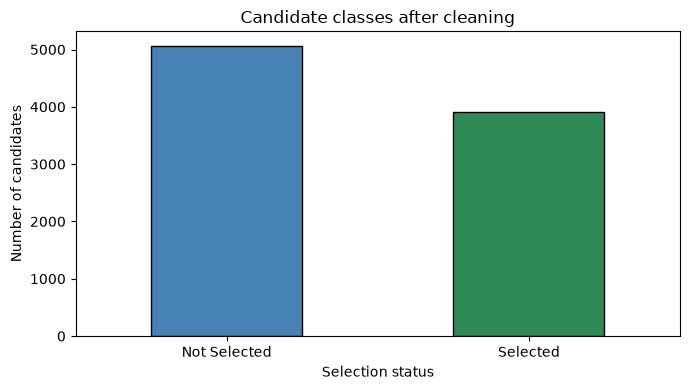

In [18]:
import matplotlib.pyplot as plt

class_counts = cleaned["selection_status"].value_counts()
print(class_counts)
class_counts.plot(kind="bar", figsize=(7, 4), color=["steelblue", "seagreen"],
                  edgecolor="black")
plt.title("Candidate classes after cleaning")
plt.xlabel("Selection status")
plt.ylabel("Number of candidates")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Read the graph:** a taller bar means more records in that class. The classes are not equally frequent, so accuracy alone does not describe all the errors. These are synthetic candidate records.

### Compare the three classifiers
Display accuracy, precision, recall and F1 from the test results already calculated in Section 5. All scores use the same 0 to 1 scale.

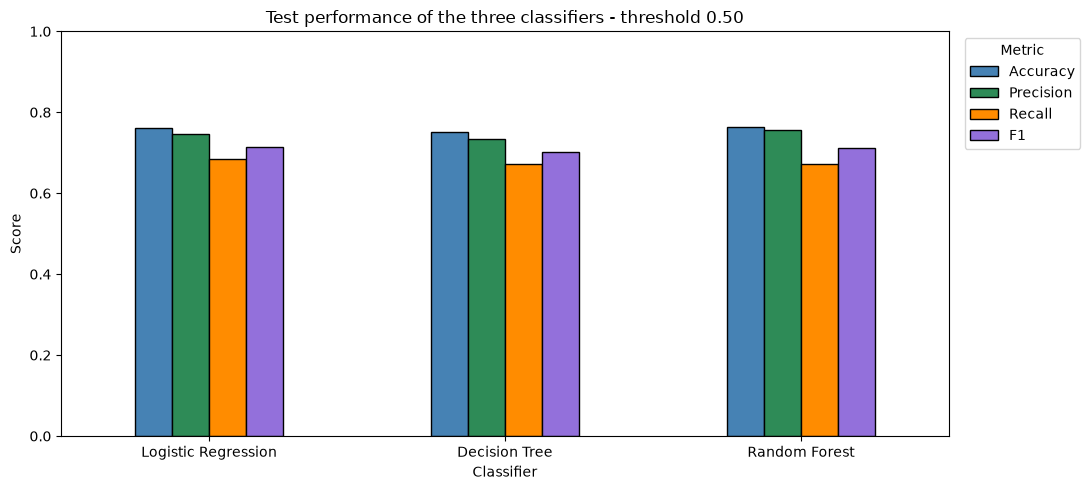

In [19]:
metrics.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(11, 5), edgecolor="black",
    color=["steelblue", "seagreen", "darkorange", "mediumpurple"])
plt.title("Test performance of the three classifiers - threshold 0.50")
plt.xlabel("Classifier")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Read the graph:** compare bars of the same colour across models. Random Forest has slightly higher test accuracy, while Logistic Regression has slightly higher test F1. We still choose the classifier using the training cross-validation result, not by switching models after inspecting the test chart.

### Confusion matrices
Use the same loop as our classification assignment to display one matrix for each classifier. Rows are actual classes; columns are predicted classes. Selected is the positive class.

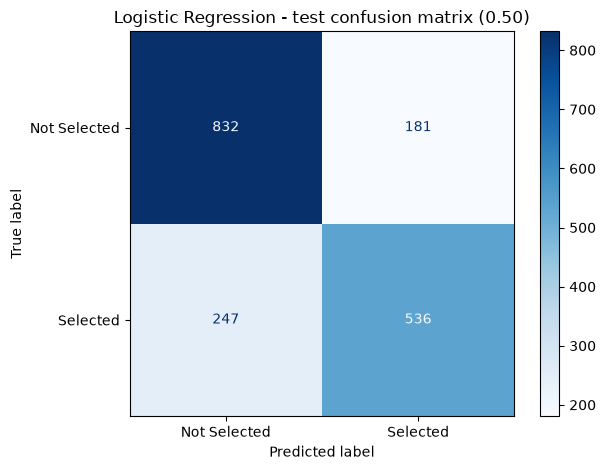

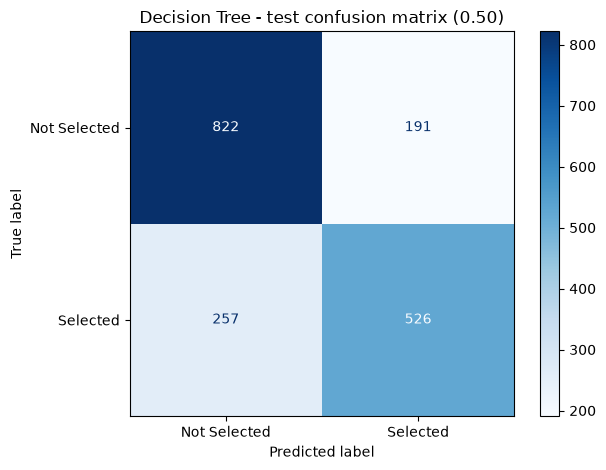

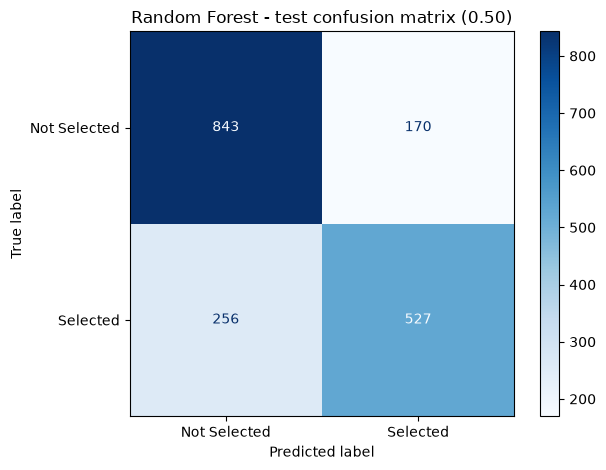

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():
    y_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1],
        display_labels=["Not Selected", "Selected"],
        cmap="Blues", values_format="d")
    plt.title(name + " - test confusion matrix (0.50)")
    plt.tight_layout()
    plt.show()

**Read each matrix:** top left = true negatives; top right = false positives (false selections); bottom left = false negatives (missed selections); bottom right = true positives. The diagonal cells are correct predictions. For Logistic Regression, the counts are **832, 181, 247 and 536** in that order; together they cover all **1,796** test records.

### Training and validation comparison
Plot the scores from Sections 4 and 7. Both series use macro F1, so the comparison measures the same quantity. Validation means five-fold cross-validation on training data, not the held-out test set.

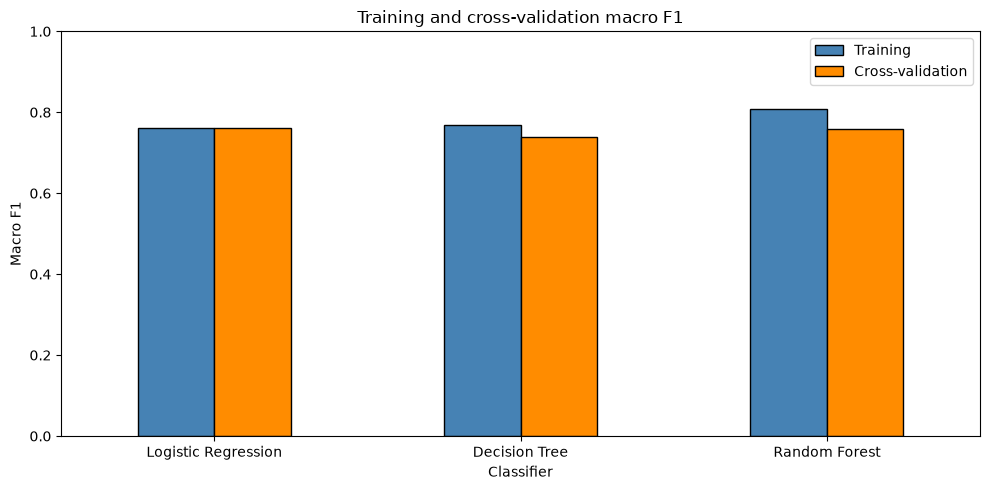

In [21]:
comparison.set_index("Model")[["Train macro F1", "CV macro F1"]].plot(
    kind="bar", figsize=(10, 5), color=["steelblue", "darkorange"],
    edgecolor="black")
plt.title("Training and cross-validation macro F1")
plt.xlabel("Classifier")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(["Training", "Cross-validation"], loc="upper right")
plt.tight_layout()
plt.show()

**Read the graph:** a larger training advantage suggests more overfitting. Random Forest shows the largest gap here. Logistic Regression has a very small gap, but that does not prove that it will generalise to real hiring data. None of these charts changes the active model or its 0.68 application threshold.

## Conclusion
We cleaned the data, used an 80/20 split, trained three classifiers and compared their results. The project uses the same saved classifier and decision policy checked in this notebook.

These are synthetic records. The results demonstrate classification, not verified real hiring performance.

Section 10 visualises the class counts, test metrics, confusion matrices and training-validation scores. The more detailed analysis remains in `Candidate_Selection_Advanced.ipynb`.